# Thực nghiệm 03 — Thử siêu tham số cho 4 mô hình trên tập A+B

Thực nghiệm sử dụng `development.csv` với 38 đặc trưng của tập A+B,
gồm 36 đặc trưng gốc và hai đặc trưng bổ sung của học kỳ 1.

Bốn mô hình dùng lại đúng cấu hình thử của lượt 02 trên tập A.
Các mô hình được đánh giá bằng cùng 5 fold phân tầng với seed 42.
Chỉ số so sánh là CV Macro-F1 trung bình.

## 1. Cấu hình và siêu tham số

In [2]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.svm import SVC
from xgboost import XGBClassifier

cwd = Path.cwd().resolve()
project_dir = next(
    (
        folder
        for folder in (cwd, *cwd.parents, cwd / "ML01_Student_Dropout")
        if (folder / "feature_b" / "common.py").is_file()
    ),
    None,
)
if project_dir is None:
    raise FileNotFoundError("Mở repo sgu-MAYHOC trong VS Code rồi chạy lại.")

sys.path.insert(0, str(project_dir / "feature_b"))
from common import evaluate, load_development

data_path = project_dir / "data" / "processed" / "development.csv"
output_dir = (
    project_dir / "experiments" / "2026-11-14_ThuThamSo_4MoHinh_TapAB_Thuong"
)

N_FOLDS = 5
SEED = 42

# Mỗi mục gồm lớp mô hình, bộ tham số và cờ chuẩn hóa cột số.
configs = {
    "Logistic Regression": (
        LogisticRegression,
        {"C": 1.0, "class_weight": "balanced", "solver": "lbfgs", "max_iter": 3000},
        True,
    ),
    "Random Forest": (
        RandomForestClassifier,
        {
            "n_estimators": 300, "max_depth": None, "min_samples_leaf": 1,
            "class_weight": "balanced", "random_state": SEED, "n_jobs": 1,
        },
        False,
    ),
    "SVM": (
        SVC,
        {"kernel": "rbf", "C": 10, "gamma": 0.001, "class_weight": "balanced"},
        True,
    ),
    "XGBoost": (
        XGBClassifier,
        {
            "n_estimators": 150, "max_depth": 4, "learning_rate": 0.1,
            "objective": "multi:softprob", "num_class": 3,
            "eval_metric": "mlogloss", "tree_method": "hist",
            "random_state": SEED, "n_jobs": 1,
        },
        False,
    ),
}

config_table = pd.DataFrame([
    {
        "Mô hình": name,
        "Tham số thiết lập": ", ".join(
            f"{key}={value!r}" for key, value in params.items()
        ),
        "Chuẩn hóa cột số": "Có" if scale_numeric else "Không",
    }
    for name, (_, params, scale_numeric) in configs.items()
])
display(config_table)

,Mô hình,Tham số thiết lập,Chuẩn hóa cột số
0,Logistic Regression,"C=1.0, class_weight='balanced', solver='lbfgs'...",Có
1,Random Forest,"n_estimators=300, max_depth=None, min_samples_...",Không
2,SVM,"kernel='rbf', C=10, gamma=0.001, class_weight=...",Có
3,XGBoost,"n_estimators=150, max_depth=4, learning_rate=0...",Không


## 2. Huấn luyện và đánh giá trên A+B

Tạo lại cách chia 5 fold như lượt 02 trên tập A. Với mỗi fold,
mô hình học trên 4 phần và dự đoán trên phần còn lại.


In [3]:
X_a, X_ab, y = load_development(data_path)

cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
folds = list(cv.split(X_a, y))

summary_rows = []
fold_tables = []

for name, (model_class, params, scale_numeric) in configs.items():
    print(f"Đang chạy {name} trên A+B...")
    model = model_class(**params)
    summary, fold_scores = evaluate(name, model, scale_numeric, "A+B", X_ab, y, folds)
    summary_rows.append(summary)
    fold_tables.append(fold_scores)

results = (
    pd.DataFrame(summary_rows)
    .sort_values("cv_macro_f1", ascending=False)
    .reset_index(drop=True)
)
fold_results = pd.concat(fold_tables, ignore_index=True)

display(results.round(6))

best = results.iloc[0]
print(f"Cao nhất lượt này: {best['model']} ({best['cv_macro_f1']:.6f})")

3539 mẫu | A: 36 cột | A+B: 38 cột
Số mẫu đăng ký 0 môn HK1: 148
Đang chạy Logistic Regression trên A+B...
Đang chạy Random Forest trên A+B...
Đang chạy SVM trên A+B...
Đang chạy XGBoost trên A+B...


,model,data,features,cv_macro_f1,oof_recall_dropout,oof_recall_enrolled,oof_recall_graduate
0,Random Forest,A+B,38,0.722734,0.754617,0.519685,0.879457
1,XGBoost,A+B,38,0.717022,0.781003,0.425197,0.917374
2,Logistic Regression,A+B,38,0.711936,0.737907,0.604724,0.816072
3,SVM,A+B,38,0.701788,0.690413,0.623622,0.817204


Cao nhất lượt này: Random Forest (0.722734)


## 3. Đối chiếu kết quả và xuất minh chứng

- **A thử:** Điểm từ thực nghiệm 02, đã làm tròn đến 6 chữ số thập phân.
- **A+B mốc:** Điểm từ các dòng `A+B` trong `experiments/feature_b/*_a_vs_ab.csv`.
- **A+B thử:** Điểm vừa chạy với cấu hình thử của lượt 02.

So **A+B thử − A thử** để xem tác động của việc thêm B khi dùng cùng cấu hình thử. 
So **A+B thử − A+B mốc** để xem tác động của việc đổi siêu tham số trên cùng tập A+B.

,Mô hình,A thử,A+B mốc,A+B thử,Thêm B (xấp xỉ),Đổi tham số trên A+B
0,Logistic Regression,0.709920,0.717317,0.711936,0.002016,-0.005381
1,Random Forest,0.722722,0.723427,0.722734,0.000012,-0.000693
2,SVM,0.702828,0.717298,0.701788,-0.001040,-0.015510
3,XGBoost,0.709446,0.708953,0.717022,0.007576,0.008069


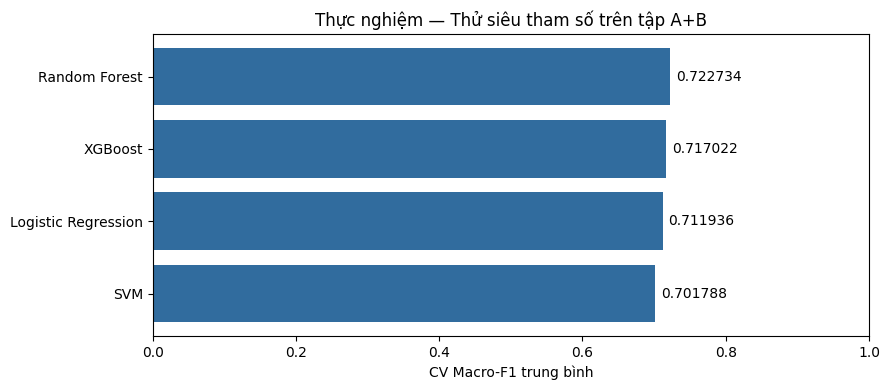

Đã lưu Excel: C:\Users\Admin\Documents\GitHub\sgu-MAYHOC\ML01_Student_Dropout\experiments\2026-11-14_ThuThamSo_4MoHinh_TapAB_Thuong\ket_qua.xlsx
Đã lưu ảnh: C:\Users\Admin\Documents\GitHub\sgu-MAYHOC\ML01_Student_Dropout\experiments\2026-11-14_ThuThamSo_4MoHinh_TapAB_Thuong\so_sanh_macro_f1.png


In [4]:
# Mã mô hình trong tên CSV và điểm lượt 02 trên tập A.
references = {
    "Logistic Regression": ("lr", 0.709920),
    "Random Forest": ("rf", 0.722722),
    "SVM": ("svm", 0.702828),
    "XGBoost": ("xgb", 0.709446),
}

ab_trial_scores = results.set_index("model")["cv_macro_f1"]
comparison_rows = []

for name, (model_code, score_a_trial) in references.items():
    csv_path = project_dir / "experiments" / "feature_b" / f"{model_code}_a_vs_ab.csv"
    baseline = pd.read_csv(csv_path)
    score_ab_base = baseline.loc[baseline["data"].eq("A+B"), "cv_macro_f1"].item()
    score_ab_trial = ab_trial_scores.loc[name]

    comparison_rows.append({
        "Mô hình": name,
        "A thử": score_a_trial,
        "A+B mốc": score_ab_base,
        "A+B thử": score_ab_trial,
        "Thêm B (xấp xỉ)": score_ab_trial - score_a_trial,
        "Đổi tham số trên A+B": score_ab_trial - score_ab_base,
    })

comparison = pd.DataFrame(comparison_rows)
display(comparison.round(6))

output_dir.mkdir(parents=True, exist_ok=True)
excel_path = output_dir / "ket_qua.xlsx"
image_path = output_dir / "so_sanh_macro_f1.png"

run_info = pd.DataFrame([{
    "Người chạy": "Lê Đỗ Hoà Thương",
    "Tập đặc trưng": "A+B",
    "Dữ liệu": "data/processed/development.csv",
    "Số mẫu": len(y),
    "Số đặc trưng": X_ab.shape[1],
    "Kiểm định chéo": "StratifiedKFold",
    "Số fold": N_FOLDS,
    "Shuffle": True,
    "Random state": SEED,
    "Chỉ số": "CV Macro-F1 trung bình",
}])

with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
    results.to_excel(writer, sheet_name="Tong hop", index=False)
    comparison.round(6).to_excel(writer, sheet_name="So sanh voi moc", index=False)
    fold_results.to_excel(writer, sheet_name="Diem tung fold", index=False)
    config_table.to_excel(writer, sheet_name="Cau hinh mo hinh", index=False)
    run_info.to_excel(writer, sheet_name="Cau hinh luot chay", index=False)

fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.barh(results["model"], results["cv_macro_f1"], color="#316C9E")
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_xlabel("CV Macro-F1 trung bình")
ax.set_title("Thực nghiệm — Thử siêu tham số trên tập A+B")
ax.bar_label(bars, fmt="%.6f", padding=4)
fig.tight_layout()
fig.savefig(image_path, dpi=180)
plt.show()

print(f"Đã lưu Excel: {excel_path}")
print(f"Đã lưu ảnh: {image_path}")

## 4. Nhận xét

- Trong lượt thử trên A+B, Random Forest 300 cây đạt CV Macro-F1 cao nhất
  (0,722734). So với cùng cấu hình trên A (0,722722), điểm gần như bằng nhau.
- XGBoost được lợi nhiều nhất khi thêm hai đặc trưng B, từ 0,709446 lên
  0,717022 (+0,007576). Đây cũng là mô hình duy nhất có cấu hình thử
  cải thiện so với cấu hình mốc trên A+B (+0,008069).
- Nếu xét cả hai cấu hình Random Forest trên A+B, cấu hình mốc 200 cây
  vẫn nhỉnh hơn cấu hình thử 300 cây (0,723427 so với 0,722734).